# SongNet Reproduction: MLP and Linear SVM Baselines

UE24CS352A Machine Learning mini-project, reproducing *SongNet: Real-time Music Classification*
(Chen Chen, Chi Zhang, Yue Zhang).

This notebook trains the two feature-based baselines on **FMA-small** (8,000 tracks, 8 balanced genres):

1. **Multilayer Perceptron (MLP)**
2. **Linear Support Vector Machine (SVM)**

Both models use the same pre-computed audio features shipped with FMA (`features.csv`), the same
shared train/val/test split, and the same evaluation metrics as the C-RNN notebook.

| Model | Accuracy reported in the paper (reference only) |
|---|---:|
| MLP | 44.88% |
| Linear SVM | 46.38% |

The numbers above are the paper's results. The results of this notebook are computed below and
saved to `results/mlp_svm/`.



## 1. Setup

In [1]:
import random
import subprocess
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

### Shared split and metric code

This cell is **identical in all notebooks**. It defines the single train/val/test split and the
evaluation metrics, so the MLP, SVM and C-RNN are trained and scored on exactly the same tracks
in the same way.

In [2]:
import hashlib
import json

import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split

SEED = 42
SPLITS = ("train", "val", "test")
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.20, "test": 0.10}

# FMA-small MP3s that are empty or truncated (reported in the FMA repository issues).
# They are dropped before splitting so that every model sees the same tracks.
EXCLUDED_TRACK_IDS = (98565, 98567, 98569, 99134, 108925, 133297)


def load_small_subset(tracks_csv, exclude=EXCLUDED_TRACK_IDS):
    """FMA-small track IDs and their top-level genre, from tracks.csv."""
    tracks = pd.read_csv(tracks_csv, index_col=0, header=[0, 1])
    small = tracks[tracks[("set", "subset")] == "small"]
    df = pd.DataFrame({"track_id": small.index.astype(int),
                       "genre": small[("track", "genre_top")].values})
    if df["genre"].isna().any():
        raise ValueError("Some FMA-small tracks have no genre_top label.")
    df = df[~df["track_id"].isin(exclude)]
    return df.sort_values("track_id").reset_index(drop=True)


def create_splits(df, seed=SEED):
    """Stratified 70/20/10 split of track IDs."""
    X, y = df["track_id"].values, df["genre"].values
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=seed)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=1/3, stratify=y_tmp, random_state=seed)
    parts = [pd.DataFrame({"track_id": ids, "genre": labels, "split": name})
             for name, ids, labels in (("train", X_tr, y_tr), ("val", X_val, y_val), ("test", X_te, y_te))]
    return pd.concat(parts, ignore_index=True).sort_values("track_id").reset_index(drop=True)


def validate_splits(splits, tolerance=0.01):
    """Raise if the manifest is malformed, overlapping or not a stratified 70/20/10 split."""
    if set(splits.columns) != {"track_id", "genre", "split"}:
        raise ValueError(f"Unexpected columns: {list(splits.columns)}")
    if splits["track_id"].duplicated().any():
        dupes = splits.loc[splits["track_id"].duplicated(), "track_id"].tolist()
        raise ValueError(f"Track IDs assigned more than once: {dupes[:10]}")
    unknown = set(splits["split"]) - set(SPLITS)
    if unknown:
        raise ValueError(f"Unknown split names: {unknown}")
    for name, frac in SPLIT_FRACTIONS.items():
        actual = (splits["split"] == name).mean()
        if abs(actual - frac) > tolerance:
            raise ValueError(f"{name} holds {actual:.3f} of tracks, expected {frac:.2f}")
    counts = pd.crosstab(splits["genre"], splits["split"])
    missing = [s for s in SPLITS if s not in counts.columns or (counts[s] == 0).any()]
    if missing:
        raise ValueError(f"Some genres are absent from split(s): {missing}")


def load_or_create_splits(tracks_csv, splits_path, overwrite=False):
    """Load splits.csv, creating it from tracks.csv only if it does not exist yet."""
    splits_path = Path(splits_path)
    if overwrite or not splits_path.exists():
        splits = create_splits(load_small_subset(tracks_csv))
        validate_splits(splits)
        splits_path.parent.mkdir(parents=True, exist_ok=True)
        splits.to_csv(splits_path, index=False)
        print(f"Created split manifest: {splits_path}")
    else:
        print(f"Loaded existing split manifest: {splits_path}")
    splits = pd.read_csv(splits_path, dtype={"track_id": int, "genre": str, "split": str})
    validate_splits(splits)
    return splits


def file_sha256(path):
    """Checksum of splits.csv; matching values in both notebooks mean they used the same split."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def audio_path(audio_dir, track_id):
    """Path of an FMA MP3, e.g. fma_small/000/000002.mp3."""
    tid = f"{int(track_id):06d}"
    return Path(audio_dir) / tid[:3] / f"{tid}.mp3"


def compute_metrics(y_true, y_pred, class_names):
    """Accuracy, macro precision/recall/F1, per-class report and confusion matrix."""
    labels = list(range(len(class_names)))
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "per_class": classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                           output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "n_samples": int(len(y_true)),
    }


def plot_confusion_matrix(cm, class_names, title, save_path=None):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set(xlabel="Predicted genre", ylabel="True genre", title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    return fig


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2))

In [3]:
IN_COLAB = "google.colab" in sys.modules

USE_DRIVE = True  # save splits.csv, results and models to Google Drive so they survive the session

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path("/content/drive/MyDrive/SongNet")
    else:
        PROJECT_ROOT = Path("/content/SongNet")
    FMA_DIR = Path("/content/fma")  # dataset on Colab's local disk (fast, re-downloaded each session)
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FMA_DIR = PROJECT_ROOT / "data"

METADATA_DIR = FMA_DIR / "fma_metadata"
AUDIO_DIR = FMA_DIR / "fma_small"
SPLITS_PATH = PROJECT_ROOT / "data" / "splits.csv"
DOWNLOAD_IF_MISSING = IN_COLAB  # never downloads the dataset outside Colab

print("Outputs saved under:", PROJECT_ROOT)
print("FMA data dir:", FMA_DIR)

RESULTS_DIR = PROJECT_ROOT / "results" / "mlp_svm"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
print("scikit-learn", sklearn.__version__)

Mounted at /content/drive
Outputs saved under: /content/drive/MyDrive/SongNet
FMA data dir: /content/fma
scikit-learn 1.6.1


## 2. Get the FMA metadata

Only `fma_metadata.zip` (342 MB) is needed here; `tracks.csv` and `features.csv` are extracted from it.

In [4]:
FMA_URL = "https://os.unil.cloud.switch.ch/fma"


def download_and_extract(archive, members=()):
    """Download an FMA archive into FMA_DIR and unzip it (optionally only some members)."""
    FMA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = FMA_DIR / f"{archive}.zip"
    print(f"Downloading {archive}.zip ...")
    subprocess.run(["wget", "-nv", "-O", str(zip_path), f"{FMA_URL}/{archive}.zip"], check=True)
    print(f"Extracting {archive}.zip ...")
    subprocess.run(["unzip", "-q", "-o", str(zip_path), *members, "-d", str(FMA_DIR)], check=True)
    zip_path.unlink()


needed = [METADATA_DIR / "tracks.csv", METADATA_DIR / "features.csv"]
if not all(p.exists() for p in needed):
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"Place tracks.csv and features.csv in {METADATA_DIR}")
    download_and_extract("fma_metadata", ["fma_metadata/tracks.csv", "fma_metadata/features.csv"])
print("Metadata ready:", [p.name for p in needed])

Extracting fma_metadata.zip ...
Metadata ready: ['tracks.csv', 'features.csv']


## 3. Shared train / validation / test split

All models use **one** split manifest, `data/splits.csv`, created by the shared code in Section 1:

- FMA-small tracks (`tracks.csv`, `set.subset == "small"`), labelled by `track.genre_top`.
- Six MP3s known to be empty or truncated are removed first (`EXCLUDED_TRACK_IDS`) so that the
  baseline models and the C-RNN see exactly the same tracks.
- Stratified 70% / 20% / 10% split with `random_state=42`.

The manifest is only generated if it does not already exist; otherwise it is loaded. Because the
split code and seed are identical in both notebooks, it comes out the same even if each notebook
creates it separately. Both notebooks print its SHA-256 checksum and store it in their saved
metrics, so we can confirm they used the identical split.

In [5]:
splits = load_or_create_splits(METADATA_DIR / "tracks.csv", SPLITS_PATH)
SPLITS_SHA256 = file_sha256(SPLITS_PATH)
CLASS_NAMES = sorted(splits["genre"].unique())  # list index = integer label
label_of = {g: i for i, g in enumerate(CLASS_NAMES)}

print(f"{len(splits)} tracks | splits.csv sha256 = {SPLITS_SHA256}")
pd.crosstab(splits["genre"], splits["split"], margins=True)[["train", "val", "test", "All"]]

Created split manifest: /content/drive/MyDrive/SongNet/data/splits.csv
7994 tracks | splits.csv sha256 = 77644b5972a1c9ec8dea69199f6660ddf8c4bd030183453140b5424b31aba57f


split,train,val,test,All
genre,,,,
Electronic,699,200,100,999
Experimental,699,200,100,999
Folk,700,200,100,1000
Hip-Hop,698,199,100,997
Instrumental,700,200,100,1000
International,700,200,100,1000
Pop,700,200,100,1000
Rock,699,200,100,999
All,5595,1599,800,7994


## 4. FMA-provided features

`features.csv` contains 518 pre-computed features per track. Each column is indexed by
(feature, statistic, coefficient): 11 librosa feature types, each summarised over the clip with
7 statistics (mean, std, skew, kurtosis, median, min, max).

The cell below lists the available feature groups and their sizes so the choice is visible.

In [6]:
features = pd.read_csv(METADATA_DIR / "features.csv", index_col=0, header=[0, 1, 2])
features.index = features.index.astype(int)

group_sizes = features.columns.get_level_values(0).value_counts().sort_index()
print(f"features.csv: {features.shape[0]} tracks x {features.shape[1]} features")
group_sizes.rename("n_columns").to_frame()

features.csv: 106574 tracks x 518 features


,n_columns
feature,
chroma_cens,84
chroma_cqt,84
chroma_stft,84
mfcc,140
rmse,7
spectral_bandwidth,7
spectral_centroid,7
spectral_contrast,49
spectral_rolloff,7


### Feature selection

The paper describes the baseline input as a 140-dimensional FMA feature vector but does not list the
columns. In `features.csv` the only feature group with exactly 140 columns is **MFCC**
(20 coefficients × 7 statistics). We therefore use the MFCC block by default. **This is our
inference, not something the paper states explicitly.**

Set `FEATURE_GROUPS = None` to use all 518 features instead (useful as a sensitivity check).

In [7]:
FEATURE_GROUPS = ["mfcc"]  # None -> all 518 FMA features

X_all = features if FEATURE_GROUPS is None else features[FEATURE_GROUPS]
print(f"Using feature groups {FEATURE_GROUPS or 'ALL'}: {X_all.shape[1]} columns")


def split_xy(name):
    part = splits[splits["split"] == name]
    missing = set(part["track_id"]) - set(X_all.index)
    if missing:
        raise KeyError(f"{len(missing)} {name} tracks have no row in features.csv")
    X = X_all.loc[part["track_id"]].to_numpy(dtype=np.float64)
    y = part["genre"].map(label_of).to_numpy()
    return X, y, part["track_id"].to_numpy()


X_train, y_train, ids_train = split_xy("train")
X_val, y_val, ids_val = split_xy("val")
X_test, y_test, ids_test = split_xy("test")

assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any()
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

Using feature groups ['mfcc']: 140 columns
train (5595, 140) | val (1599, 140) | test (800, 140)


## 5. Preprocessing and model selection

- **Standardisation:** each model is a `Pipeline(StandardScaler, classifier)`. The scaler is fit
  on the **training split only**, then applied unchanged to validation and test data.
- **Model selection:** a small hyperparameter grid is trained on the training split and scored
  on the **validation split**. The configuration with the best validation accuracy is kept.
- **Test split:** not touched until the final evaluation in Section 8.

The paper does not report the baselines' hyperparameters, so the grids below are our choices.

In [8]:
def select_on_validation(make_classifier, grid):
    """Fit one pipeline per grid point on train, score on val, return (best_model, table)."""
    rows, best_model, best_acc = [], None, -1.0
    for params in ParameterGrid(grid):
        model = make_pipeline(StandardScaler(), make_classifier(**params))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_train, y_train)
        row = {
            **params,
            "train_acc": accuracy_score(y_train, model.predict(X_train)),
            "val_acc": accuracy_score(y_val, model.predict(X_val)),
            "converged": not any(issubclass(w.category, ConvergenceWarning) for w in caught),
        }
        rows.append(row)
        print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
        if row["val_acc"] > best_acc:
            best_model, best_acc = model, row["val_acc"]
    table = pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)
    return best_model, table

## 6. Multilayer Perceptron

`sklearn.neural_network.MLPClassifier` with ReLU hidden layers, Adam, and early stopping.
Early stopping holds out 10% of the **training** split internally; it never sees the validation
or test split. We tune the hidden-layer sizes and the L2 penalty `alpha`.

In [9]:
def make_mlp(hidden_layer_sizes, alpha):
    return MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, activation="relu",
                         solver="adam", learning_rate_init=1e-3, batch_size=64, max_iter=500,
                         early_stopping=True, n_iter_no_change=20, random_state=SEED)


mlp_grid = {
    "hidden_layer_sizes": [(128,), (256,), (256, 128), (512, 256)],
    "alpha": [1e-4, 1e-3, 1e-2, 1e-1],
}
mlp_model, mlp_search = select_on_validation(make_mlp, mlp_grid)
mlp_search.to_csv(RESULTS_DIR / "mlp_validation_search.csv", index=False)
mlp_search.head()

{'alpha': 0.0001, 'hidden_layer_sizes': (128,), 'train_acc': 0.7015, 'val_acc': 0.5241, 'converged': True}
{'alpha': 0.0001, 'hidden_layer_sizes': (256,), 'train_acc': 0.7757, 'val_acc': 0.5303, 'converged': True}
{'alpha': 0.0001, 'hidden_layer_sizes': (256, 128), 'train_acc': 0.8191, 'val_acc': 0.5228, 'converged': True}
{'alpha': 0.0001, 'hidden_layer_sizes': (512, 256), 'train_acc': 0.9601, 'val_acc': 0.526, 'converged': True}
{'alpha': 0.001, 'hidden_layer_sizes': (128,), 'train_acc': 0.7017, 'val_acc': 0.5235, 'converged': True}
{'alpha': 0.001, 'hidden_layer_sizes': (256,), 'train_acc': 0.7764, 'val_acc': 0.5303, 'converged': True}
{'alpha': 0.001, 'hidden_layer_sizes': (256, 128), 'train_acc': 0.9206, 'val_acc': 0.5197, 'converged': True}
{'alpha': 0.001, 'hidden_layer_sizes': (512, 256), 'train_acc': 0.6988, 'val_acc': 0.5316, 'converged': True}
{'alpha': 0.01, 'hidden_layer_sizes': (128,), 'train_acc': 0.6744, 'val_acc': 0.5303, 'converged': True}
{'alpha': 0.01, 'hidden_laye

,alpha,hidden_layer_sizes,train_acc,val_acc,converged
0,0.1000,"(256,)",0.715460,0.532833,True
1,0.0010,"(512, 256)",0.698838,0.531582,True
2,0.0010,"(256,)",0.776408,0.530331,True
3,0.0001,"(256,)",0.775693,0.530331,True
4,0.0100,"(128,)",0.674352,0.530331,True


## 7. Linear Support Vector Machine

`sklearn.svm.LinearSVC` (linear kernel, squared-hinge loss, one-vs-rest for the 8 classes) on the
same standardised features. We tune the regularisation strength `C`.

In [10]:
def make_svm(C):
    return LinearSVC(C=C, dual="auto", max_iter=50_000, random_state=SEED)


svm_grid = {"C": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]}
svm_model, svm_search = select_on_validation(make_svm, svm_grid)
svm_search.to_csv(RESULTS_DIR / "svm_validation_search.csv", index=False)
svm_search.head()

{'C': 0.0001, 'train_acc': 0.4953, 'val_acc': 0.4615, 'converged': True}
{'C': 0.0003, 'train_acc': 0.5112, 'val_acc': 0.4722, 'converged': True}
{'C': 0.001, 'train_acc': 0.5278, 'val_acc': 0.4822, 'converged': True}
{'C': 0.003, 'train_acc': 0.5394, 'val_acc': 0.4934, 'converged': True}
{'C': 0.01, 'train_acc': 0.5444, 'val_acc': 0.4903, 'converged': True}
{'C': 0.03, 'train_acc': 0.5464, 'val_acc': 0.4909, 'converged': True}
{'C': 0.1, 'train_acc': 0.5492, 'val_acc': 0.4941, 'converged': True}
{'C': 0.3, 'train_acc': 0.5514, 'val_acc': 0.4916, 'converged': True}
{'C': 1.0, 'train_acc': 0.5519, 'val_acc': 0.4903, 'converged': True}


,C,train_acc,val_acc,converged
0,0.100,0.549240,0.494059,True
1,0.003,0.539410,0.493433,True
2,0.300,0.551385,0.491557,True
3,0.030,0.546381,0.490932,True
4,0.010,0.544415,0.490306,True


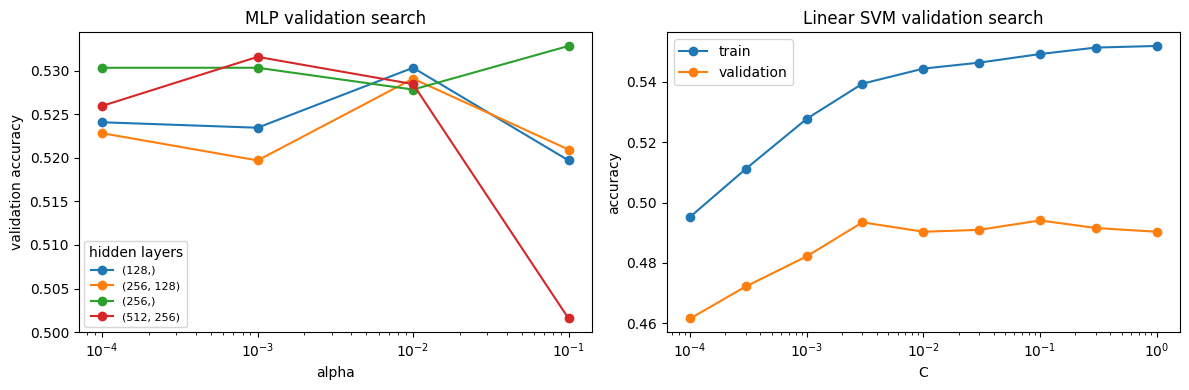

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (hidden, grp) in mlp_search.groupby(mlp_search["hidden_layer_sizes"].astype(str)):
    grp = grp.sort_values("alpha")
    axes[0].plot(grp["alpha"], grp["val_acc"], marker="o", label=hidden)
axes[0].set(xscale="log", xlabel="alpha", ylabel="validation accuracy", title="MLP validation search")
axes[0].legend(title="hidden layers", fontsize=8)
s = svm_search.sort_values("C")
axes[1].plot(s["C"], s["train_acc"], marker="o", label="train")
axes[1].plot(s["C"], s["val_acc"], marker="o", label="validation")
axes[1].set(xscale="log", xlabel="C", ylabel="accuracy", title="Linear SVM validation search")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_search.png", dpi=150)
plt.show()

## 8. Final test evaluation

The selected MLP and SVM (trained on the training split only) are evaluated once on the held-out
test split: accuracy, macro precision, macro recall, macro F1, per-class metrics and a confusion matrix.

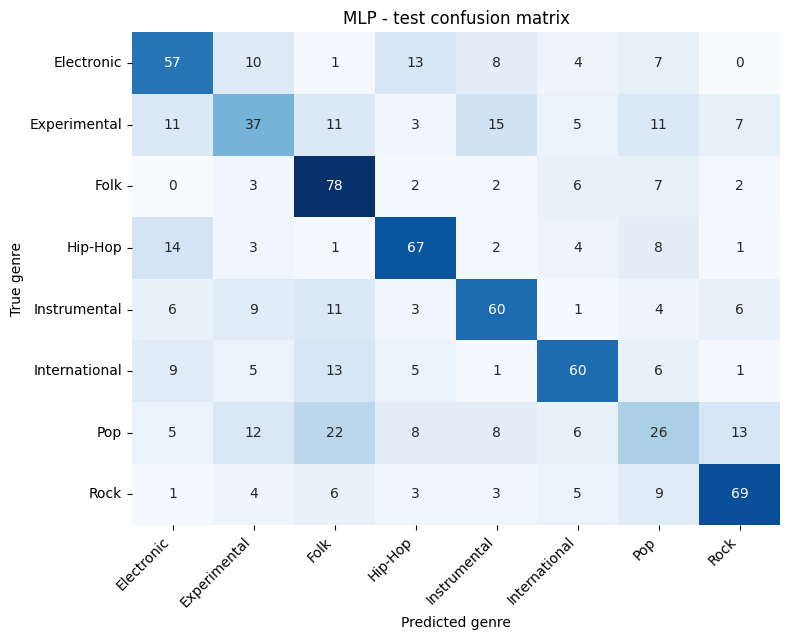

               precision  recall  f1-score  support
Electronic         0.553   0.570     0.562  100.000
Experimental       0.446   0.370     0.404  100.000
Folk               0.545   0.780     0.642  100.000
Hip-Hop            0.644   0.670     0.657  100.000
Instrumental       0.606   0.600     0.603  100.000
International      0.659   0.600     0.628  100.000
Pop                0.333   0.260     0.292  100.000
Rock               0.697   0.690     0.693  100.000
accuracy           0.568   0.568     0.568    0.568
macro avg          0.561   0.568     0.560  800.000
weighted avg       0.561   0.568     0.560  800.000 



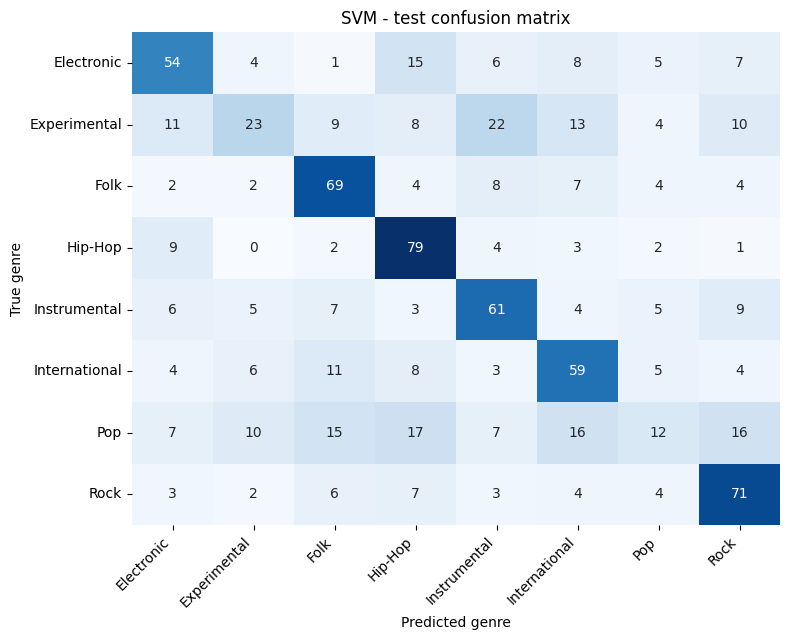

               precision  recall  f1-score  support
Electronic         0.562   0.540     0.551  100.000
Experimental       0.442   0.230     0.303  100.000
Folk               0.575   0.690     0.627  100.000
Hip-Hop            0.560   0.790     0.656  100.000
Instrumental       0.535   0.610     0.570  100.000
International      0.518   0.590     0.551  100.000
Pop                0.293   0.120     0.170  100.000
Rock               0.582   0.710     0.640  100.000
accuracy           0.535   0.535     0.535    0.535
macro avg          0.508   0.535     0.508  800.000
weighted avg       0.508   0.535     0.508  800.000 



In [12]:
final = {}
predictions = pd.DataFrame({"track_id": ids_test,
                            "true_genre": [CLASS_NAMES[i] for i in y_test]})

for name, model, search in [("mlp", mlp_model, mlp_search), ("svm", svm_model, svm_search)]:
    y_pred = model.predict(X_test)
    metrics = compute_metrics(y_test, y_pred, CLASS_NAMES)
    metrics["val_accuracy"] = float(search.loc[0, "val_acc"])
    metrics["selected_params"] = {k: (list(v) if isinstance(v, tuple) else v)
                                  for k, v in model[-1].get_params().items()
                                  if k in search.columns}
    final[name] = metrics
    predictions[f"{name}_pred"] = [CLASS_NAMES[i] for i in y_pred]

    plot_confusion_matrix(np.array(metrics["confusion_matrix"]), CLASS_NAMES,
                          f"{name.upper()} - test confusion matrix",
                          RESULTS_DIR / f"{name}_confusion_matrix.png")
    plt.show()
    print(pd.DataFrame(metrics["per_class"]).T.round(3), "\n")
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")

predictions.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

In [13]:
summary = pd.DataFrame({
    name: {k: final[name][k] for k in
           ["val_accuracy", "accuracy", "precision_macro", "recall_macro", "f1_macro"]}
    for name in final
}).T.rename(columns={"accuracy": "test_accuracy"})

save_json({
    "models": final,
    "feature_groups": FEATURE_GROUPS or "all",
    "n_features": int(X_all.shape[1]),
    "class_names": CLASS_NAMES,
    "split_counts": splits["split"].value_counts().to_dict(),
    "splits_sha256": SPLITS_SHA256,
    "seed": SEED,
    "sklearn_version": sklearn.__version__,
}, RESULTS_DIR / "metrics.json")
summary.round(4)

,val_accuracy,test_accuracy,precision_macro,recall_macro,f1_macro
mlp,0.5328,0.5675,0.5606,0.5675,0.5602
svm,0.4941,0.5350,0.5084,0.5350,0.5085


## 9. Comparison with the paper

`Paper (reference)` is copied from the paper; `This run` is computed above.

In [14]:
PAPER_REFERENCE = {"mlp": 0.4488, "svm": 0.4638}

comparison = pd.DataFrame({
    "Model": ["Multilayer Perceptron", "Linear SVM"],
    "Paper (reference)": [PAPER_REFERENCE["mlp"], PAPER_REFERENCE["svm"]],
    "This run (test accuracy)": [final["mlp"]["accuracy"], final["svm"]["accuracy"]],
})
comparison["Difference"] = comparison["This run (test accuracy)"] - comparison["Paper (reference)"]
comparison.to_csv(RESULTS_DIR / "comparison_with_paper.csv", index=False)
comparison.style.format({c: "{:.2%}" for c in comparison.columns if c != "Model"})

,Model,Paper (reference),This run (test accuracy),Difference
0,Multilayer Perceptron,44.88%,56.75%,11.87%
1,Linear SVM,46.38%,53.50%,7.12%


## Notes and limitations

- **Feature set:** the 140-dimensional MFCC block is our inference of the paper's 140 features.
  Re-run with `FEATURE_GROUPS = None` to compare against all 518 FMA features.
- **Split:** the paper's exact split is not published. We use our own stratified 70/20/10 split
  (`data/splits.csv`), so small differences from the reported accuracies are expected.
- **Hyperparameters:** the baselines' settings are not given in the paper; ours are chosen on the
  validation split.
- **Saved outputs:** `results/mlp_svm/` (metrics, validation searches, confusion matrices,
  test predictions) and `models/mlp.joblib`, `models/svm.joblib` (scaler + classifier pipelines).